

## Questions d'analyse

1. Quel type d'album est le plus représenté dans le dataset : album, single ou compilation ?
2. Comment la popularité des albums varie-t-elle selon leur type ?
3. Comment le nombre de sorties musicales évolue-t-il au fil des années ?
4. Quels sont les artistes les plus représentés dans le dataset ?
5. Existe-t-il une relation entre le nombre de morceaux d'un album et sa popularité ?

In [4]:
from pathlib import Path
import pandas as pd

chemin_csv = Path("../data/processed/spotify_albums_clean.csv")

df = pd.read_csv(chemin_csv)

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (438948, 20)


,track_name,track_id,track_number,duration_ms,album_type,total_tracks,album_name,release_date,label,album_popularity,album_id,artist_id,artist_0,artist_1,artist_2,artist_3,artist_4,artist_5,artist_6,duration_sec
0,Amazing Grace,6mN8nzCXWUeT5LWEcG1Utx,5,555521,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,3VoHMFQzFr9v163HXRvfo2,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,555.521
1,Silent Night,58sgjtx3FOnBBEOd3BQE6C,8,535041,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,3VoHMFQzFr9v163HXRvfo2,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,535.041
2,Ancient Canyons,45tQJhm0WSk5VWMZK3FsLK,1,545855,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,3VoHMFQzFr9v163HXRvfo2,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,545.855
3,Pacha Mama Medicina,3VFD7QqkJSg0OR6yBwKl7A,6,305241,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,3VoHMFQzFr9v163HXRvfo2,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,305.241
4,Palace Of Light,7LwJV5BEIC9BQnzvaBSyCc,7,351060,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,3VoHMFQzFr9v163HXRvfo2,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,351.060


In [2]:
types_albums = df["album_type"].value_counts()
print(types_albums)

album_type
album          307729
single          86750
compilation     44469
Name: count, dtype: int64


In [3]:
pourcentages = df["album_type"].value_counts(normalize=True) * 100
print(pourcentages.round)

<bound method Series.round of album_type
album          70.106026
single         19.763161
compilation    10.130813
Name: proportion, dtype: float64>


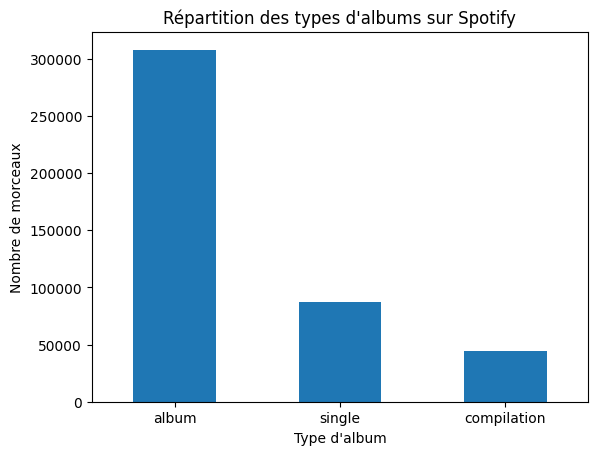

In [13]:
import matplotlib.pyplot as plt


repartition = df["album_type"].value_counts()


repartition.plot(kind="bar")

plt.title("Répartition des types d'albums sur Spotify")
plt.xlabel("Type d'album")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=0)


plt.savefig("../figures/02_repartition_album.png",
            bbox_inches="tight",
            dpi=300)


plt.show()

In [6]:
popularite_type = df.groupby("album_type")["album_popularity"].mean()
print(popularite_type.round(2))

album_type
album          19.04
compilation    21.88
single          9.86
Name: album_popularity, dtype: float64


In [7]:
mediane_type = df.groupby("album_type")["album_popularity"].median()

print(mediane_type)

album_type
album          10.0
compilation    14.0
single          2.0
Name: album_popularity, dtype: float64


album_type
album          19.04
compilation    21.88
single          9.86
Name: album_popularity, dtype: float64


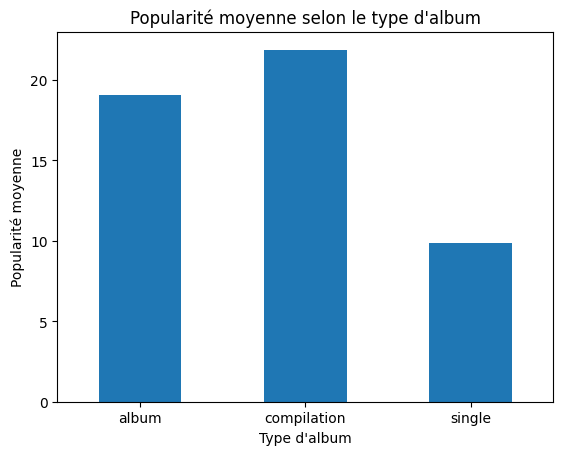

In [16]:

popularite_type = df.groupby("album_type")["album_popularity"].mean()


print(popularite_type.round(2))


popularite_type.plot(kind="bar")

plt.title("Popularité moyenne selon le type d'album")
plt.xlabel("Type d'album")
plt.ylabel("Popularité moyenne")
plt.xticks(rotation=0)


plt.savefig("../figures/01_popularite_album.png",
            bbox_inches="tight",
            dpi=300)

plt.show()

Le dataset Spotify étudié contient principalement des morceaux issus d'albums. Les singles sont moins représentés, tandis que les compilations constituent la catégorie la moins présente. Cette répartition montre que les données sont majoritairement composées de morceaux appartenant à des albums.

La popularité moyenne varie selon le type d'album. Dans ce dataset, les compilations présentent la popularité moyenne la plus élevée, suivies des albums. Les singles ont la popularité moyenne la plus faible. Cette observation décrit les données étudiées, mais ne permet pas d'affirmer que le type d'album est la cause de ces différences de popularité.

annee
1886        4
1899       20
1900       14
1901       50
1912       13
        ...  
2019    22306
2020    28272
2021    29866
2022    41295
2023    64970
Name: count, Length: 87, dtype: int64


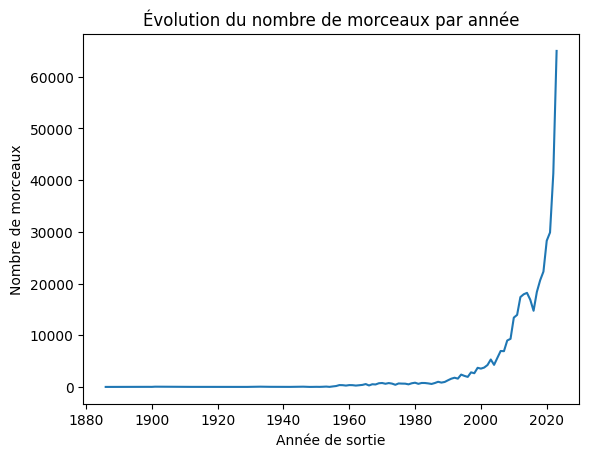

In [18]:
import matplotlib.pyplot as plt


df["release_date"] = pd.to_datetime(
    df["release_date"],
    errors="coerce",
    utc=True
)


df["annee"] = df["release_date"].dt.year


sorties_par_annee = df["annee"].value_counts().sort_index()

print(sorties_par_annee)


sorties_par_annee.plot(kind="line")

plt.title("Évolution du nombre de morceaux par année")
plt.xlabel("Année de sortie")
plt.ylabel("Nombre de morceaux")


plt.savefig("../figures/03_morceaux_par_annee.png",
            bbox_inches="tight",
            dpi=300)

plt.show()

**Analyse de l'évolution du nombre de morceaux par année**

Le graphique montre une augmentation progressive du nombre de morceaux enregistrés dans le dataset au fil du temps. Cette hausse devient particulièrement importante à partir des années 2000 et s'accélère dans les années récentes.

Cependant, le nombre de morceaux observés dépend aussi de la manière dont le dataset a été constitué. Cette évolution ne permet donc pas, à elle seule, de conclure que la production musicale mondiale a augmenté dans les mêmes proportions.

In [13]:
df[df["annee"] < 1950][
    ["track_name", "artist_0", "album_name", "release_date"]
].head(20)

,track_name,artist_0,album_name,release_date
18815,"Fidelio, Op. 72 / Act 1: ""O Wär' Ich Schon Mit...",Ludwig van Beethoven,"Beethoven: Fidelio, Op. 72: O Wär' Ich Schon M...",1929-01-01 00:00:00+00:00
22617,Die Fledermaus (Short Version): Part 1,Johann Strauss II,Strauss: Die Fledermaus: Part 1,1929-01-01 00:00:00+00:00
22618,Die Fledermaus (Short Version): Part 4,Johann Strauss II,Strauss: Die Fledermaus: Part 4,1929-01-01 00:00:00+00:00
22619,Die Fledermaus (Short Version): Part 9,Johann Strauss II,Strauss: Die Fledermaus: Part 9,1929-01-01 00:00:00+00:00
22620,Die Fledermaus (Short Version): Part 2,Johann Strauss II,Strauss: Die Fledermaus: Part 2,1929-01-01 00:00:00+00:00
22621,Die Fledermaus (Short Version): Part 7,Johann Strauss II,Strauss: Die Fledermaus: Part 7,1929-01-01 00:00:00+00:00
24565,"Der Rosenkavalier, Op. 59, Trv 227: ""Hab Mir'S...",Richard Strauss,"Strauss: Der Rosenkavalier, Op. 59, Trv 227: H...",1929-01-01 00:00:00+00:00
24566,"Ariadne Auf Naxos, Trv 228: Zerbinetta'S Scene",Richard Strauss,Strauss: Zerbinetta'S Scene,1933-01-01 00:00:00+00:00
46813,Pennies From Heaven (With Teddy Wilson & His O...,Billie Holiday,Lady Day: The Complete Billie Holiday On Colum...,1936-01-01 00:00:00+00:00
46814,Why Was I Born? (With Teddy Wilson & His Orche...,Billie Holiday,Lady Day: The Complete Billie Holiday On Colum...,1936-01-01 00:00:00+00:00


Dates anciennes au 1er janvier : 250
Total des dates anciennes : 283


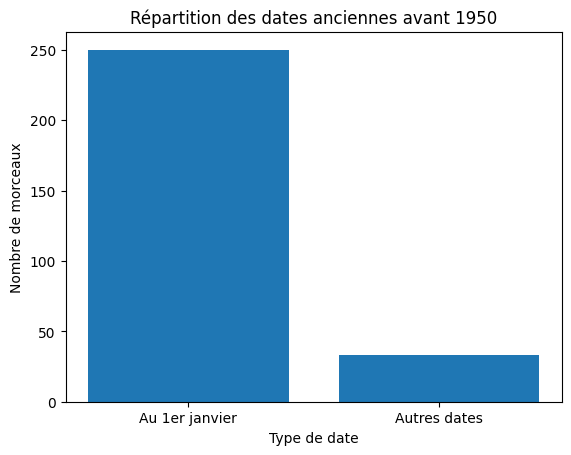

In [19]:

dates_anciennes = df[df["annee"] < 1950]


dates_1er_janvier = (
    (dates_anciennes["release_date"].dt.month == 1) &
    (dates_anciennes["release_date"].dt.day == 1)
).sum()

total_dates_anciennes = len(dates_anciennes)

print("Dates anciennes au 1er janvier :", dates_1er_janvier)
print("Total des dates anciennes :", total_dates_anciennes)


plt.bar(
    ["Au 1er janvier", "Autres dates"],
    [dates_1er_janvier, total_dates_anciennes - dates_1er_janvier]
)

plt.title("Répartition des dates anciennes avant 1950")
plt.xlabel("Type de date")
plt.ylabel("Nombre de morceaux")

# Enregistrer le graphique
plt.savefig("../figures/04_dates_anciennes.png",
            bbox_inches="tight",
            dpi=300)

plt.show()

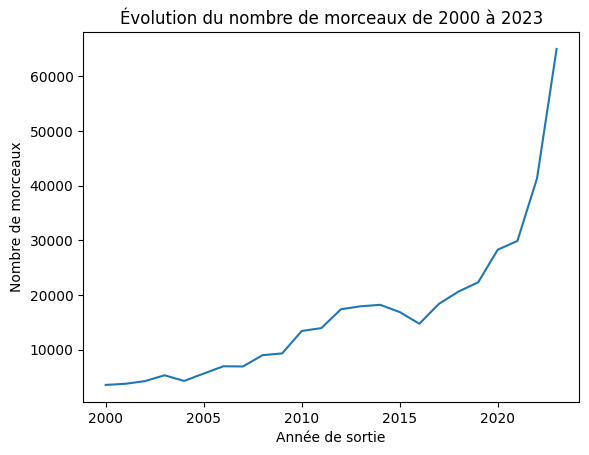

In [20]:
import matplotlib.pyplot as plt

df_recent = df[
    (df["annee"] >= 2000) &
    (df["annee"] <= 2023)
]


sorties_recentes = df_recent["annee"].value_counts().sort_index()


sorties_recentes.plot(kind="line")

plt.title("Évolution du nombre de morceaux de 2000 à 2023")
plt.xlabel("Année de sortie")
plt.ylabel("Nombre de morceaux")


plt.savefig("../figures/04_morceaux_depuis_2000.png",
            bbox_inches="tight",
            dpi=300)

plt.show()

### Analyse de l'évolution des sorties musicales entre 2000 et 2023

Le graphique montre une augmentation globale du nombre de morceaux présents dans le dataset entre 2000 et 2023.

On observe une progression relativement régulière entre 2000 et 2014, suivie d'une baisse temporaire autour de 2015-2016. À partir de 2017, le nombre de morceaux augmente de nouveau, avec une forte accélération à partir de 2019. L'année 2023 présente le nombre de morceaux le plus élevé de la période étudiée.

Cette évolution décrit la répartition des morceaux dans le dataset Spotify étudié. Elle ne permet pas d'affirmer que la production musicale mondiale a augmenté dans les mêmes proportions, car le dataset peut être influencé par sa méthode de collecte et sa couverture des années récentes.

artist_0
Johann Sebastian Bach     3109
Johnny Cash               2825
The Karaoke Channel       1952
Raphael                   1718
Singer's Edge Karaoke     1520
ProSound Karaoke Band     1371
Sound Healing Center      1350
Piano Dreamers            1267
Molotov Cocktail Piano    1264
Taylor Swift              1188
Name: count, dtype: int64


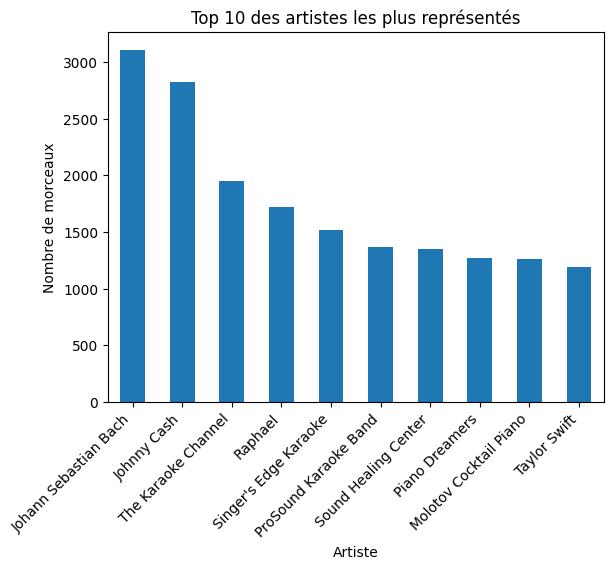

In [21]:

import matplotlib.pyplot as plt


top_artistes = df["artist_0"].value_counts().head(10)

print(top_artistes)


top_artistes.plot(kind="bar")

plt.title("Top 10 des artistes les plus représentés")
plt.xlabel("Artiste")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=45, ha="right")


plt.savefig("../figures/05_top_artistes.png",
            bbox_inches="tight",
            dpi=300)

plt.show()

,album_type,duration_ms,duree_moyenne_minutes
0,album,214290.352895,3.571506
1,compilation,226311.981605,3.771866
2,single,218164.853925,3.636081


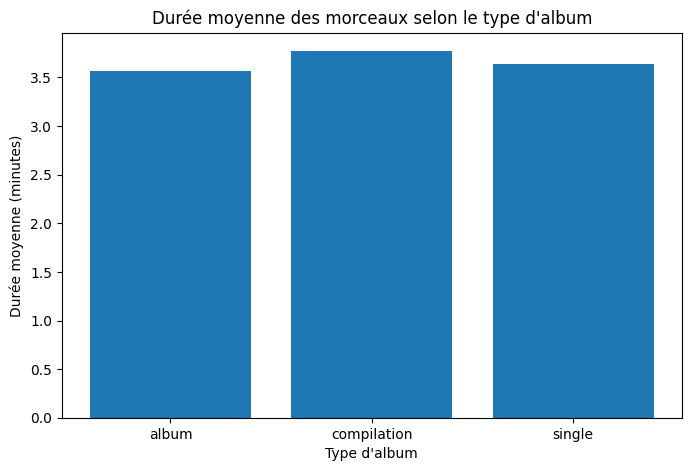

In [22]:
import matplotlib.pyplot as plt

# Calculer la durée moyenne par type d'album
duree_par_type = (
    df.groupby("album_type")["duration_ms"]
    .mean()
    .reset_index()
)

# Convertir la durée en minutes
duree_par_type["duree_moyenne_minutes"] = (
    duree_par_type["duration_ms"] / 60000
)

display(duree_par_type)

# Créer le graphique
plt.figure(figsize=(8, 5))

plt.bar(
    duree_par_type["album_type"],
    duree_par_type["duree_moyenne_minutes"]
)

plt.title("Durée moyenne des morceaux selon le type d'album")
plt.xlabel("Type d'album")
plt.ylabel("Durée moyenne (minutes)")

# Enregistrer le graphique dans figures
plt.savefig("../figures/06_duree_moyenne_album.png",
            bbox_inches="tight",
            dpi=300)

plt.show()

Cette analyse compare la durée moyenne des morceaux selon le type d'album. Elle permet d'identifier si les morceaux issus des albums, singles ou compilations ont des durées moyennes différentes. Les résultats décrivent uniquement les morceaux présents dans le dataset Spotify étudié.

In [8]:


types_albums = pd.DataFrame({
    "album_type": ["album", "single", "compilation"],
    "description_type": [
        "Album",
        "Single",
        "Compilation"
    ]
})

display(types_albums)

,album_type,description_type
0,album,Album
1,single,Single
2,compilation,Compilation


In [9]:

nb_lignes_avant = len(df)


df_joint = df.merge(
    types_albums,
    on="album_type",
    how="left",
    validate="many_to_one"
)


nb_lignes_apres = len(df_joint)

print("Lignes avant :", nb_lignes_avant)
print("Lignes après :", nb_lignes_apres)

assert nb_lignes_avant == nb_lignes_apres

display(df_joint.head())

Lignes avant : 438948
Lignes après : 438948


,track_name,track_id,track_number,duration_ms,album_type,total_tracks,album_name,release_date,label,album_popularity,...,artist_id,artist_0,artist_1,artist_2,artist_3,artist_4,artist_5,artist_6,duration_sec,description_type
0,Amazing Grace,6mN8nzCXWUeT5LWEcG1Utx,5,555521,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,...,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,555.521,Album
1,Silent Night,58sgjtx3FOnBBEOd3BQE6C,8,535041,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,...,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,535.041,Album
2,Ancient Canyons,45tQJhm0WSk5VWMZK3FsLK,1,545855,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,...,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,545.855,Album
3,Pacha Mama Medicina,3VFD7QqkJSg0OR6yBwKl7A,6,305241,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,...,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,305.241,Album
4,Palace Of Light,7LwJV5BEIC9BQnzvaBSyCc,7,351060,album,9,Deep Peace Experience,2015-06-09 00:00:00+00:00,Mountain Music Inc,6,...,002nyxOMwdc9EgNEo7ETcF,Radiancematrix,NaN,NaN,NaN,NaN,NaN,NaN,351.060,Album


In [10]:
print(
    df_joint["description_type"]
    .isna()
    .sum(),
    "valeurs manquantes après la jointure"
)

0 valeurs manquantes après la jointure


Une jointure gauche a été réalisée entre le dataset Spotify et une table de référence des types d'albums. La clé utilisée est album_type. Le contrôle du nombre de lignes avant et après la jointure permet de vérifier que cette opération n'a pas ajouté ou supprimé de morceaux. La validation many_to_one garantit qu'un type d'album correspond à une seule ligne de la table de référence

In [11]:

nb_sans_correspondance = df_joint["description_type"].isna().sum()

print("Morceaux sans correspondance :", nb_sans_correspondance)

Morceaux sans correspondance : 0
